## 1. Подключение библиотек


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from google.colab import drive

np.random.seed(42)
print("Библиотеки загружены")

drive.mount('/content/drive')

Библиотеки загружены


## 2. Генерация датасета

Для работы используем генератор `make_regression` из `sklearn.datasets`.
Он создаёт синтетический набор данных для задачи линейной регрессии:
признаки X и целевую переменную y, которая линейно зависит от X плюс шум.

Параметры:
- n_samples=1000 — число объектов;
- n_features=5 — число признаков (по заданию ≥ 2, у нас 5);
- n_informative=3 — только 3 признака реально влияют на y,
  остальные 2 — шумовые. Это пригодится при L1-регуляризации:
  она должна "обнулить" лишние веса;
- noise=10.0 — уровень шума;
- bias=5.0 — свободный член;
- coef=True — вернуть истинные коэффициенты для сравнения;
- random_state=42 — фиксируем случайность.

Итого весов у модели будет 6: один bias и пять коэффициентов
при признаках. Это ≥ 3, как требует задание.

In [ ]:
X, y, true_coef = make_regression(
    n_samples=1000,
    n_features=5,
    n_informative=3,
    noise=10.0,
    bias=5.0,
    coef=True,
    random_state=42
)

print("Размер X:", X.shape)
print("Размер y:", y.shape)
print("Истинные коэффициенты:", np.round(true_coef, 2))

Размер X: (1000, 5)
Размер y: (1000,)
Истинные коэффициенты: [ 0.   46.07 16.82  0.   18.99]


## 3. Разделение на train/test и масштабирование

Делим данные на обучающую и тестовую выборки в пропорции 80/20.

Зачем масштабировать:
градиентный спуск чувствителен к масштабу признаков. Если один признак
измеряется в тысячах, а другой — в десятых, шаги по весам будут
сильно различаться, и обучение пойдёт плохо. StandardScaler приводит
каждый признак к среднему 0 и стандартному отклонению 1.

Важный нюанс: scaler обучаем ТОЛЬКО на train, а к test применяем уже
обученный. Иначе произойдёт утечка данных (data leakage).

Затем добавляем столбец единиц в начало матрицы X. Это трюк, чтобы
свободный член (bias) обрабатывался как обычный вес w[0]:
тогда X @ w сразу даёт прогноз. Такой столбец НЕ масштабируется.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Столбец единиц для bias
X_train_b = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
X_test_b  = np.hstack([np.ones((X_test_scaled.shape[0], 1)),  X_test_scaled])

print("X_train_b:", X_train_b.shape)
print("X_test_b: ", X_test_b.shape)

X_train_b: (800, 6)
X_test_b:  (200, 6)


## 4. Функция потерь и её градиент

В качестве функции потерь используем MSE (Mean Squared Error):

    Q(w) = (1/n) * Σ (ŷ_i - y_i)²,   где ŷ = X @ w

Градиент MSE по вектору весов w:

    ∇Q(w) = (2/n) * Xᵀ @ (X @ w - y)

Здесь:
- X — матрица признаков (n × d), включая столбец единиц;
- y — вектор целевых значений (n,);
- w — вектор весов (d,);
- n — число объектов.

Эти две формулы — основа всего дальнейшего: и обычного GD, и SGD,
и версии с регуляризацией.

In [ ]:
def mse_loss(X, y, w):
    """Среднеквадратичная ошибка."""
    n = len(y)
    pred = X @ w
    return np.mean((pred - y) ** 2)

def mse_grad(X, y, w):
    """Градиент MSE по w."""
    n = len(y)
    pred = X @ w
    return (2 / n) * X.T @ (pred - y)

## 5. Обычный (пакетный) градиентный спуск

Алгоритм из задания:

1) Инициализировать веса w и ε.
2) Цикл по числу итераций:
   - вычислить градиент по всей выборке;
   - обновить веса: w^k = w^{k-1} - η · ∇Q(w^{k-1});
   - если ||w^k - w^{k-1}|| < ε — остановиться.

Здесь η — скорость обучения (learning rate).

В функции сразу заложена поддержка L1-регуляризации через
soft-thresholding. Это понадобится на шаге 10 (наш вариант — чётный).
Пока что use_l1=False, и функция работает как чистая версия.

Почему soft-thresholding, а не обычный субградиент:
у |w| нет производной в нуле. Если просто добавлять λ·sign(w),
веса будут "залипать" рядом с нулём, но не обнуляться точно.
Soft-thresholding даёт ровно нули — а нам нужен отбор признаков.

In [ ]:
def gradient_descent(X, y, eta=0.01, lam=0.0, max_iter=2000,
                     eps=1e-6, use_l1=False):
    """
    Обычный градиентный спуск.
    lam — коэффициент регуляризации (0 = без регуляризации).
    use_l1 — если True, применяем L1 через soft-thresholding.
    """
    n, d = X.shape
    w = np.zeros(d)
    losses = []
    w_history = [w.copy()]

    for k in range(max_iter):
        w_old = w.copy()

        # Шаг по MSE
        w = w - eta * mse_grad(X, y, w)

        # L1: soft-thresholding для всех весов, КРОМЕ bias w[0]
        if use_l1 and lam > 0:
            for j in range(1, d):
                if w[j] > eta * lam:
                    w[j] -= eta * lam
                elif w[j] < -eta * lam:
                    w[j] += eta * lam
                else:
                    w[j] = 0.0

        losses.append(mse_loss(X, y, w))
        w_history.append(w.copy())

        if np.linalg.norm(w - w_old) < eps:
            print(f"Остановка на итерации {k+1}")
            break

    return w, losses, w_history

## 6. Первый запуск GD

Запускаем градиентный спуск при η = 0.05 и смотрим на веса и MSE.
Смотрим на два числа:
- MSE на train — насколько хорошо модель описывает обучающие данные;
- MSE на test — насколько хорошо она обобщает.

Если MSE train и test близки — модель не переобучена.
Если MSE test резко хуже — есть переобучение (при L1 это исправится).

Также строим график функции потерь по итерациям: должно быть быстрое
падение и выход на плато.

Остановка на итерации 153
Веса: [ 3.523 -0.807 46.092 16.843  0.052 19.667]
MSE на train: 109.477
MSE на test:  96.263


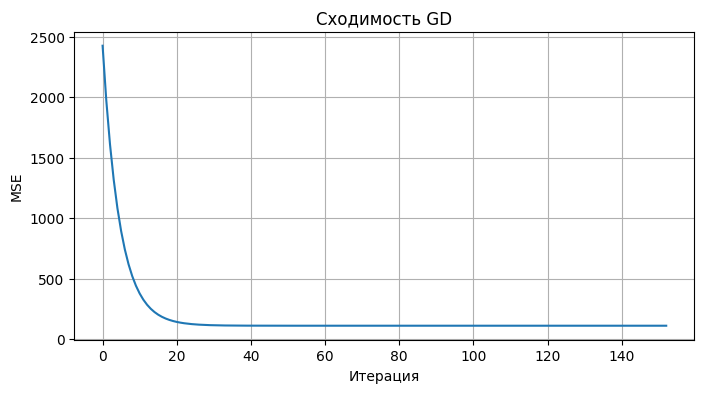

In [ ]:
w_gd, losses_gd, _ = gradient_descent(X_train_b, y_train, eta=0.05, max_iter=1000)

print("Веса:", np.round(w_gd, 3))
print("MSE на train:", round(mse_loss(X_train_b, y_train, w_gd), 3))
print("MSE на test: ", round(mse_loss(X_test_b, y_test, w_gd), 3))
plt.figure(figsize=(8,4))
plt.plot(losses_gd)
plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.title("Сходимость GD")
plt.grid(True)
plt.show()

## 7. Как скорость обучения влияет на сходимость

Берём несколько значений η: очень маленькое (0.001), умеренные
(0.01, 0.05, 0.1) и большое (0.5). Для каждого запускаем GD и
рисуем кривые MSE от итерации на одном графике.

Ожидаемое поведение:
- η = 0.001 — почти не двигается, слишком медленно;
- η = 0.01 — падает, но медленно;
- η = 0.05 и 0.1 — быстро и стабильно;
- η = 0.5 — скорее всего колебания или расходимость.

Практический вывод: скорость обучения нужно подбирать. Слишком
маленькая — долго, слишком большая — не сходится.

Остановка на итерации 153
Остановка на итерации 77
Остановка на итерации 9


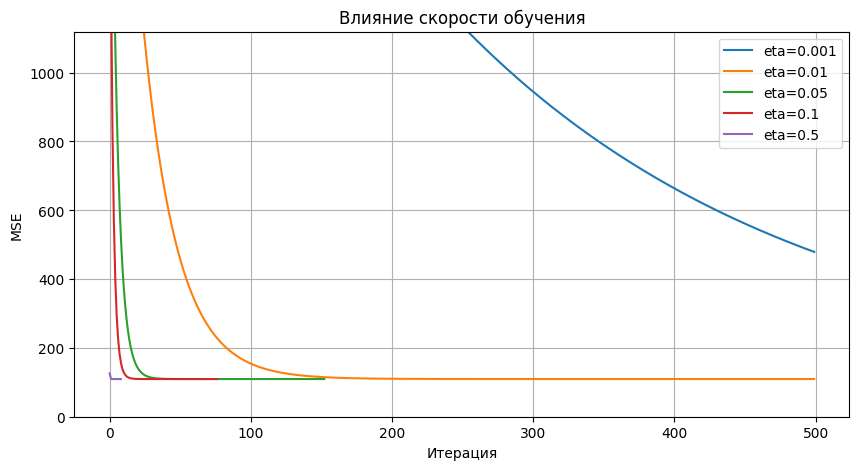

In [ ]:
etas = [0.001, 0.01, 0.05, 0.1, 0.5]

plt.figure(figsize=(10,5))
for eta in etas:
    _, losses, _ = gradient_descent(X_train_b, y_train, eta=eta, max_iter=500)
    plt.plot(losses, label=f"eta={eta}")

plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.title("Влияние скорости обучения")
plt.legend()
plt.grid(True)
plt.ylim(0, np.percentile(losses_gd, 95) * 2)
plt.show()

## 8. Стохастический градиентный спуск (SGD)

Отличие от обычного GD: на каждом шаге используется не вся выборка,
а ОДИН случайный объект. Градиент по нему:

    ∇Q_i(w) = 2 · x_iᵀ · (x_i · w - y_i)

Обновление: w := w - η · ∇Q_i(w).

Цикл организован по эпохам:
- эпоха — один проход по всем объектам;
- перед эпохой индексы перемешиваются, чтобы порядок не влиял;
- за одну эпоху делается n обновлений (у GD — 1).

Это делает SGD быстрее по эпохам, но шумнее — градиент по одному
объекту сильно варьируется.

L1-регуляризация здесь тоже реализована через soft-thresholding.

In [ ]:
def sgd(X, y, eta=0.01, lam=0.0, epochs=50, use_l1=False, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    losses_per_epoch = []

    for epoch in range(epochs):
        idx = rng.permutation(n)
        for i in idx:
            xi = X[i:i+1]
            yi = y[i:i+1]

            grad = 2 * xi.T @ (xi @ w - yi)
            w = w - eta * grad

            if use_l1 and lam > 0:
                for j in range(1, d):
                    if w[j] > eta * lam:
                        w[j] -= eta * lam
                    elif w[j] < -eta * lam:
                        w[j] += eta * lam
                    else:
                        w[j] = 0.0

        losses_per_epoch.append(mse_loss(X, y, w))

    return w, losses_per_epoch

w_sgd, losses_sgd = sgd(X_train_b, y_train, eta=0.01, epochs=50)

print("Веса SGD:", np.round(w_sgd, 3))
print("MSE test SGD:", round(mse_loss(X_test_b, y_test, w_sgd), 3))

Веса SGD: [ 3.271 -1.111 45.832 17.304  0.469 20.253]
MSE test SGD: 100.744


## 9. Сравнение GD и SGD

Сравнивать корректно по ЭПОХАМ, а не по отдельным обновлениям:
- за одну эпоху GD делает 1 обновление;
- за одну эпоху SGD делает n обновлений.

Поэтому по оси X — эпоха.

Ожидаемое поведение:
- SGD обгоняет GD по эпохам, потому что успевает сделать в n раз
  больше шагов;
- кривая SGD шумнее — это плата за стохастичность;
- GD плавный, но требует больше эпох, чтобы достичь того же MSE.

Вывод: SGD эффективнее по времени на больших данных, но требует
аккуратного подбора η и может не сойтись точно к минимуму.

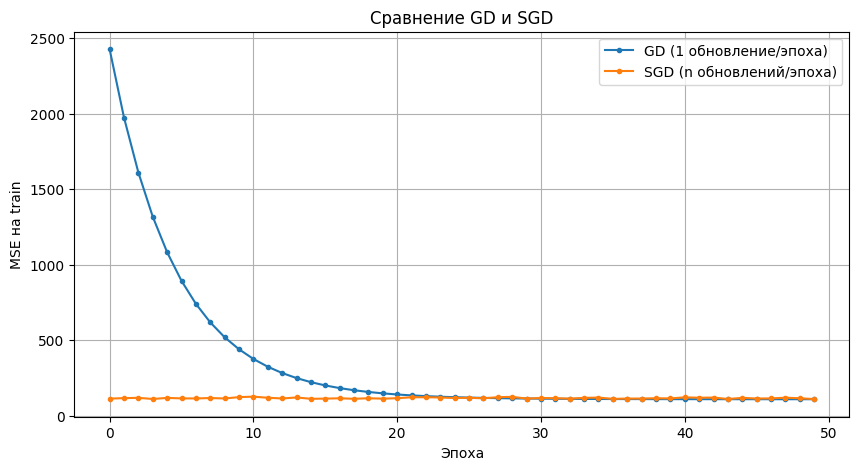

In [ ]:
epochs = 50
w_gd2, losses_gd2, _ = gradient_descent(X_train_b, y_train, eta=0.05, max_iter=epochs)

plt.figure(figsize=(10,5))
plt.plot(losses_gd2, label="GD (1 обновление/эпоха)", marker='o', markersize=3)
plt.plot(losses_sgd,  label="SGD (n обновлений/эпоха)", marker='o', markersize=3)
plt.xlabel("Эпоха")
plt.ylabel("MSE на train")
plt.title("Сравнение GD и SGD")
plt.legend()
plt.grid(True)
plt.show()

## 10. L1-регуляризация (чётный вариант)

L1 добавляет к функции потерь штраф:

    Q_L1(w) = MSE(w) + λ · Σ_{j≠0} |w_j|

Bias w[0] не регуляризуется: он не должен сжиматься.

Особенность L1: она не просто уменьшает веса, а обнуляет часть
из них — выполняет отбор признаков. У нас 5 признаков, из которых
только 3 информативных, так что L1 должна занулить примерно 2 веса.

Как реализуем: проксимальный шаг (soft-thresholding).
После шага по MSE применяем к каждому w_j (кроме bias):

    если  w_j >  ηλ  →  w_j -= ηλ
    если  w_j < -ηλ  →  w_j += ηλ
    иначе            →  w_j = 0

Это "подтягивает" маленькие веса ровно к нулю.

Берём 20 значений λ логарифмически: от 0.001 до 1000.
Для каждого обучаем модель и сохраняем веса и MSE.

In [ ]:
lambdas = np.logspace(-3, 3, 20)
weights_l1 = []
mse_train_l1 = []
mse_test_l1 = []

for lam in lambdas:
    w, _, _ = gradient_descent(
        X_train_b, y_train,
        eta=0.05, lam=lam, max_iter=500, use_l1=True
    )
    weights_l1.append(w[1:])          # без bias
    mse_train_l1.append(mse_loss(X_train_b, y_train, w))
    mse_test_l1.append(mse_loss(X_test_b, y_test, w))

weights_l1 = np.array(weights_l1)
print("Готово. Форма:", weights_l1.shape)

Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 153
Остановка на итерации 151
Остановка на итерации 150
Остановка на итерации 150
Остановка на итерации 149
Остановка на итерации 139
Остановка на итерации 123
Остановка на итерации 123
Остановка на итерации 123
Остановка на итерации 123
Готово. Форма: (20, 5)


### График: как веса зависят от λ

По оси X — log10(λ), по оси Y — значения весов.
Каждая линия — отдельный признак.

Ожидаемое: с ростом λ веса уменьшаются, и часть из них становится
ровно 0. Это визуальное доказательство того, что L1 работает как
отбор признаков.

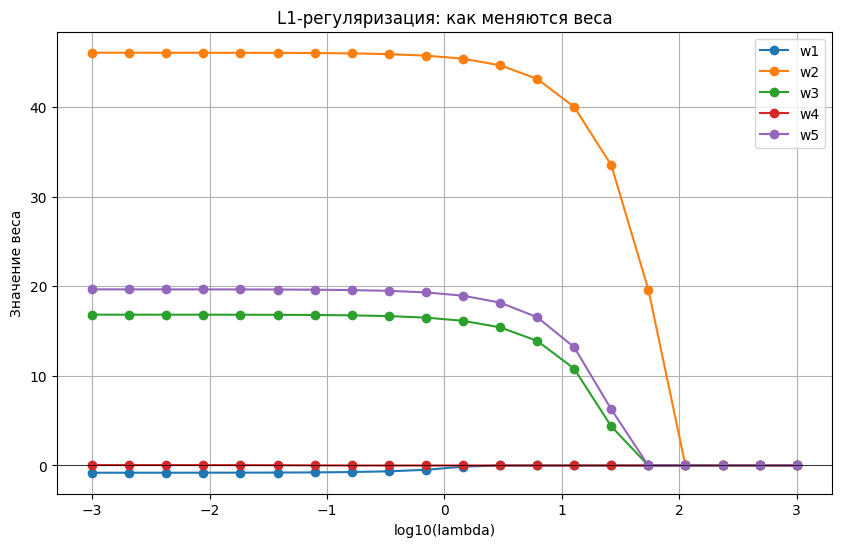

In [ ]:
plt.figure(figsize=(10,6))
for j in range(weights_l1.shape[1]):
    plt.plot(np.log10(lambdas), weights_l1[:, j], marker='o', label=f"w{j+1}")

plt.axhline(0, color='black', linewidth=0.5)
plt.xlabel("log10(lambda)")
plt.ylabel("Значение веса")
plt.title("L1-регуляризация: как меняются веса")
plt.legend()
plt.grid(True)
plt.show()

### График: ошибка на тесте от λ

Смотрим, при каком λ тестовая ошибка минимальна.
Слишком маленькая λ — переобучение, слишком большая — недообучение.
Оптимум — где-то посередине.

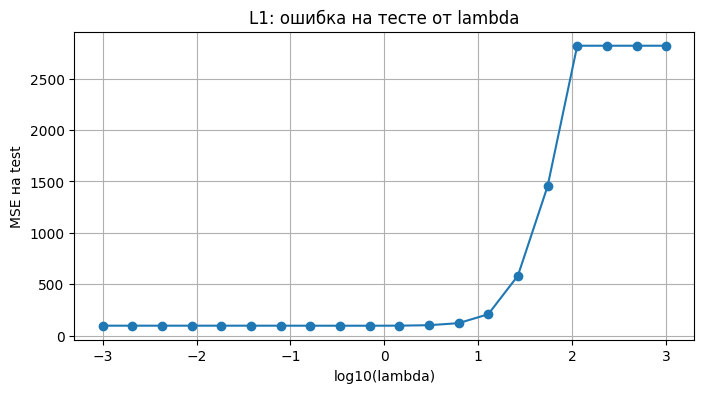

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(np.log10(lambdas), mse_test_l1, marker='o')
plt.xlabel("log10(lambda)")
plt.ylabel("MSE на test")
plt.title("L1: ошибка на тесте от lambda")
plt.grid(True)
plt.show()

## Итоговые выводы

1. Скорость обучения.
   Слишком маленькое η (0.001) даёт очень медленную сходимость.
   Слишком большое (0.5) — колебания и расходимость.
   Рабочий диапазон в нашем случае — 0.01–0.1, оптимум около 0.05.

2. GD vs SGD.
   SGD быстрее по эпохам, потому что за одну эпоху делает n обновлений.
   Но SGD шумнее: градиент по одному объекту сильно варьируется.
   GD стабильнее, но требует больше эпох.

3. L1-регуляризация.
   С ростом λ веса сжимаются. Часть из них становится ровно нулём,
   что означает отбор признаков: модель оставляет только значимые
   признаки, шумовые отбрасываются.
   Тестовая ошибка имеет оптимум по λ: слишком маленькое → переобучение,
   слишком большое → недообучение.

4. Итог.
   Комбинация SGD + L1 — практичный подход: быстрое обучение и
   автоматический отбор признаков.